In [167]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error         # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler        # 정규화 클래스


In [168]:
df= pd.read_csv('data/manhattan.csv')
df = df.loc[:,'rent':'has_gym']
df[:3]

,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym
0,2550,0.0,1,480,9,2.0,17,1,1,0,0,1,1,0,1
1,11500,2.0,2,2000,4,1.0,96,0,0,0,0,0,0,0,0
2,4500,1.0,1,916,2,51.0,29,0,1,0,1,1,1,0,0


In [169]:
data = df.iloc[:,1:].values
label = df.iloc[:,0].values


In [170]:
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [171]:
poly = PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
train_poly.shape

(2654, 119)

In [172]:
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [173]:
alpha_list = [0.001,0.01,0.1,0,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list : 
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)



In [174]:
train_score
test_score

[0.7739551100120288,
 0.7739618443762412,
 0.7740283280579189,
 0.7679396968250058,
 0.7746173878031442,
 0.7770677619201038,
 0.7731081365304112]

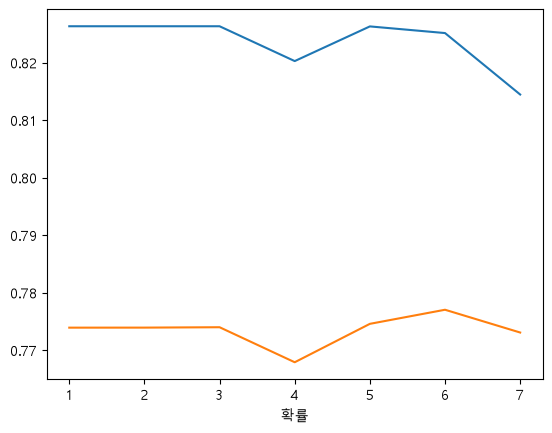

In [175]:
no_list  = np.arange(1,8)
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha번호')
plt.xlabel('확률')
plt.show()

In [176]:
ridge = Ridge(10)
ridge.fit(train_scaled,train_label)
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)

train정확도 :  0.8251720581216038
test정확도 :  0.7770677619201038


In [177]:
print("train정확도 : ",score)
print("test정확도 : ",score2)

train정확도 :  0.8251720581216038
test정확도 :  0.7770677619201038


In [178]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
predict = lr.predict(test_poly)
# print("예측 값 : ",predict)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)


train정확도 :  0.8263560338124024
test정확도 :  0.7739543607710775
